# DSS and homotaurine reviewer-response experiments

Inspect supplied real-molecule predictions, trained ASNs and baselines. This is the extension requested by the editor, separate from manuscript v24's three-site benchmark. Couplings come from supplied historical fitted rows; no new experimental spectrum is claimed. Homotaurine's temperature label remains unresolved.

Here energies are shifted and divided by the positive scale $s=-J_{MM}$; the four targets are in ascending order. Principal frequencies are differences of the upper three physical levels. Illustrative intensities require a specified preparation and observable.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from experiments.paper import ROOT
print('Repository:', ROOT)

Repository: /home/al/Documents/MNRKAN/NMRKan


In [2]:
from experiments.molecules.paths import REFERENCE_ROOT
from nmrkan.physics.three_ch2 import EXAMPLES, hamiltonian
from nmrkan.physics.real_molecules import analytical_eigenvalues, analytical_frequencies
rows=[]
for name,example in EXAMPLES.items():
    parameters=np.array(example['parameters'])
    np.testing.assert_allclose(analytical_eigenvalues(parameters),np.linalg.eigvalsh(hamiltonian(*parameters)),atol=1e-11)
    rows.append({'molecule':name,**dict(zip(['f12_Hz','f23_Hz','f13_Hz'],analytical_frequencies(parameters)))})
pd.DataFrame(rows)

,molecule,f12_Hz,f23_Hz,f13_Hz
0,DSS (31 July 2026 email; fit labeled 298 K),3.708572,4.666649,8.375221
1,Homotaurine (15 August 2026 email; temperature...,1.967923,2.185440,4.153363


In [3]:
rows=[]
for molecule in ['dss','homotaurine']:
    for domain in ['local','broad']:
        result=json.loads((REFERENCE_ROOT/molecule/domain/'comparison.json').read_text())
        for method,score in result['evaluations'].items():
            rows.append(dict(molecule=molecule,domain=domain,method=method,frequency_rmse_hz=score['frequency_rmse_hz']))
pd.DataFrame(rows)

,molecule,domain,method,frequency_rmse_hz
0,dss,local,ASN,0.002999
1,dss,local,OLS degree 2,0.002786
2,dss,local,OLS degree 4,0.000077
3,dss,local,ASN coefficients rounded to 10 decimals,0.002999
4,dss,broad,ASN,0.144956
5,dss,broad,OLS degree 2,0.140741
6,dss,broad,OLS degree 4,0.057619
7,dss,broad,ASN coefficients rounded to 10 decimals,0.144956
8,homotaurine,local,ASN,0.002135
9,homotaurine,local,OLS degree 2,0.002050


## Verify the saved neural model and its symbolic expression
Each domain has five seeds, selected by validation error. This check reloads the selected checkpoint and compares its predictions with the extracted four-variable formula on held-out rows. It does not refit coefficients.

In [4]:
import torch
import sympy as sp
from nmrkan.models import KharKAN
from experiments.molecules.train import model_predict
for molecule in ['dss','homotaurine']:
    for domain in ['local','broad']:
        folder=REFERENCE_ROOT/molecule/domain
        comparison=json.loads((folder/'comparison.json').read_text())
        state=torch.load(folder/f"seed_{comparison['selected_seed']}.pt",map_location='cpu',weights_only=True)
        model=KharKAN(tuple(state['architecture']),include_abs=False).double()
        model.switch_to_sparsemax();model.load_state_dict(state['state_dict'])
        conditioning=tuple(np.array(state[k]) for k in ['input_mean','input_std','output_mean','output_std'])
        with np.load(folder/'dataset.npz') as data:
            x=data['features'][data['test_indices'][:100]]
        formulas=json.loads((folder/'learned_formulas.json').read_text())
        fn=sp.lambdify(sp.symbols('xA xX u v'),[sp.sympify(e) for e in formulas['formulas']],'numpy',cse=True)
        symbolic=np.column_stack([np.broadcast_to(v,len(x)) for v in fn(*x.T)])
        np.testing.assert_allclose(symbolic,model_predict(model,x,conditioning),atol=1e-8,rtol=0)
        print(molecule,domain,'selected seed',comparison['selected_seed'],'verified')

dss local selected seed 44 verified
dss broad selected seed 45 verified
homotaurine local selected seed 45 verified
homotaurine broad selected seed 45 verified


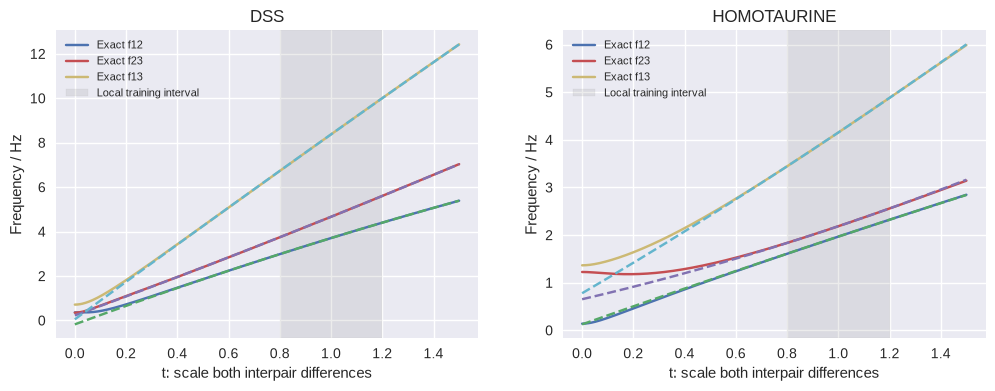

In [5]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,molecule in zip(axes,['dss','homotaurine']):
    frame=pd.read_csv(REFERENCE_ROOT/molecule/'local/cross_section_comparison.csv')
    for label in [12,23,13]:
        ax.plot(frame.t,frame[f'exact_f{label}_hz'],label=f'Exact f{label}')
        ax.plot(frame.t,frame[f'asn_f{label}_hz'],'--')
    ax.axvspan(.8,1.2,color='grey',alpha=.15,label='Local training interval')
    ax.set(title=molecule.upper(),xlabel='t: scale both interpair differences',ylabel='Frequency / Hz')
    ax.legend(fontsize=8)
plt.show()

The section scales both nearest-neighbour differences by $t$. The shaded local interval is training-domain interpolation; values outside it test extrapolation. DSS and homotaurine broad datasets are identical, not independent repeats.

To rebuild all reports from the supplied artifacts:
```bash
python -m experiments.molecules --from-reference
```
To retrain, follow the four commands in [the guide](../docs/reproducing_the_paper.md#molecular-extension). The [reviewer response map](../docs/reviewer_response.md) identifies the remaining literature and external-method comparisons. The available OLS and physics baselines do not establish a state-of-the-art advantage.